# 05 · LightGBM contra `ML_base`

`ML_base` es un HistGradientBoosting (scikit-learn) global con pérdida Poisson (LOG #19–#21, `02_modelos`). Aquí se
prueba **LightGBM** en el mismo lugar. Lo único que cambia es el regresor; todo lo demás es idéntico al backtest:

| | `ML_base` | LightGBM |
|---|---|---|
| Features | `features.BASE` (lags ≥ 3, medias, clase SB, familia, calendario…) | las mismas, de `features.parquet` |
| Objetivo | `y_entreno / escala` (serie limpia, sin los meses bajos del total) | el mismo |
| Walk-forward | h = 3, reentrenamiento mensual, datos ≤ origen | los mismos orígenes |
| Set evaluado | SKUs vivos con ≥ 13 meses de historia | las mismas filas (9,416 en validación y 10,301 en prueba) |
| Selección | hiperparámetros A, B y C con la regla WAPE + sesgo en validación | 4 configuraciones, la misma regla y solo validación |

Código en `src/comparar_lgbm.py`. Este notebook solo lee sus salidas (`lgbm_*.parquet`, `meta_lgbm.json`) y no
modifica nada de los notebooks 01–04.

**Configuraciones probadas** (todas con `random_state = 0` y `deterministic = True`):

- `L_A`: traducción directa de los hiperparámetros A de `ML_base` (Poisson, lr 0.05, 300 árboles, 31 hojas, 50 obs.
  por hoja). Comparada con `ML_base`, **aísla el efecto del algoritmo**.
- `L_bag`: `L_A` con muestreo de filas y columnas al 80 % y L2 = 1, que HistGradientBoosting no ofrece.
- `L_C`: más profundo y lento (lr 0.03, 600 árboles, 63 hojas), con muestreo de columnas al 80 % y L2.
- `L_tweedie`: `L_A` con pérdida **Tweedie** (potencia 1.5) en lugar de Poisson. Tweedie modela una masa en cero más
  una cola positiva, que es la forma de la demanda intermitente. HistGradientBoosting no tiene esta pérdida.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, FMT_MILES
from metricas import resumen, adopta, por_origen, wape, sesgo
from jerarquico import regla_estado

aplicar()
pd.set_option("display.width", 220, "display.max_columns", 40)
RES = RAIZ / "data" / "processed" / "resultados"
FIG = RAIZ / "reports" / "figuras"
meta = json.loads((RES / "meta_lgbm.json").read_text(encoding="utf-8"))
L = list(meta["hiper"])
ELEGIDO = meta["elegido"]
PERIODOS = ["validacion", "prueba"]

d = {}
for p in PERIODOS:
    x = pd.read_parquet(RES / f"lgbm_{p}.parquet")
    jer = pd.read_parquet(RES / f"pronosticos_{p}_jer.parquet")[["id_articulo", "origen", "estado_fam", "TD_mix_k3", "TD_mix_k12", "TD_estado"]]
    x = x.merge(jer, on=["id_articulo", "origen"], validate="1:1")
    x["estado"] = x.estado_fam
    assert np.allclose(regla_estado(x), x.TD_estado), "TD_estado no se reproduce"
    d[p] = x
print(f"LightGBM {meta['lightgbm']} · elegido en validación: {ELEGIDO}")
print({p: len(x) for p, x in d.items()})

LightGBM 4.7.0 · elegido en validación: L_tweedie
{'validacion': 9416, 'prueba': 10301}


## 1. Hiperparámetros (solo validación)

La referencia es `L_A`. Un candidato la reemplaza si baja el WAPE en ≥ 0.5 pp, gana en ≥ 2/3 de los orígenes y no
empeora el |sesgo| en más de 1 pp (`metricas.adopta`). Entre los que cumplen, gana el de menor WAPE.

In [2]:
v = d["validacion"]
t = resumen(v, L)[["WAPE", "sesgo", "MASE", "RMSSE", "WAPE_total"]]
t["gana_a_L_A"] = [np.nan if m == "L_A" else (por_origen(v, [m, "L_A"]).pipe(lambda x: (x[m] < x.L_A).mean())) for m in L]
t["cumple_regla"] = [None if m == "L_A" else adopta(v, m, "L_A") for m in L]
t["seg_por_origen"] = pd.Series(meta["segundos_por_origen"])
print(t.round(3).to_string())
print(f"\nElegido: {ELEGIDO}")

            WAPE  sesgo   MASE  RMSSE  WAPE_total  gana_a_L_A cumple_regla  seg_por_origen
L_A        0.461  0.158  0.759  0.655       0.210         NaN         None           1.673
L_bag      0.466  0.174  0.758  0.653       0.218       0.333        False           1.586
L_C        0.449  0.122  0.738  0.647       0.186       0.750         True           3.890
L_tweedie  0.441  0.113  0.709  0.639       0.175       0.917         True           1.575

Elegido: L_tweedie


## 2. Resultado principal: `L_tweedie` contra `ML_base`

Se muestra también `TD_estado`, el modelo vigente para los maduros (LOG #45). La columna `cumple vs X` aplica la regla
de adopción con X como referencia.

In [3]:
MOD = [ELEGIDO, "L_A", "ML_base", "TD_estado"]
filas = []
for p in PERIODOS:
    x = d[p]
    r = resumen(x, MOD)[["WAPE", "sesgo", "MASE", "RMSSE", "WAPE_total"]]
    for m in MOD:
        po = por_origen(x, [m, "ML_base"])
        filas.append({"periodo": p, "modelo": m, **r.loc[m].to_dict(),
                      "gana_origenes_vs_ML": f"{(po[m] < po.ML_base).sum()}/{len(po)}" if m != "ML_base" else "",
                      "cumple vs ML_base": adopta(x, m, "ML_base") if m != "ML_base" else "",
                      "cumple vs TD_estado": adopta(x, m, "TD_estado") if m != "TD_estado" else ""})
principal = pd.DataFrame(filas).set_index(["periodo", "modelo"])
print(principal.round(4).to_string())

                        WAPE   sesgo    MASE   RMSSE  WAPE_total gana_origenes_vs_ML cumple vs ML_base cumple vs TD_estado
periodo    modelo                                                                                                         
validacion L_tweedie  0.4406  0.1130  0.7087  0.6389      0.1749                9/12              True                True
           L_A        0.4615  0.1582  0.7591  0.6553      0.2101                7/12             False               False
           ML_base    0.4693  0.1932  0.7880  0.6663      0.2227                                                     False
           TD_estado  0.4556  0.1520  0.7712  0.6593      0.2042                9/12              True                    
prueba     L_tweedie  0.4912  0.0376  0.9332  0.7391      0.1019                8/13             False               False
           L_A        0.4938  0.0389  0.9495  0.7444      0.1033                6/13             False               False
           ML_ba

**Lectura.** En **validación**, `L_tweedie` le gana con claridad a `ML_base`: baja el WAPE en 2.9 pp
(0.441 vs 0.469), gana en 9 de 12 orígenes, recorta el sesgo de +19 % a +11 % y también le gana a `TD_estado`. Con
solo esa evidencia lo adoptaríamos.

En **prueba** la ventaja desaparece: WAPE 0.491 vs 0.490, 8 de 13 orígenes y sesgo +3.8 % vs +3.5 %. No cumple la
regla ni contra `ML_base` ni contra `TD_estado` (0.482). Lo único que conserva es un mejor **MASE**
(0.933 vs 0.952). El MASE pondera igual a cada SKU, así que eso indica que mejora en los SKUs chicos, que pesan poco
en el WAPE (§4).

## 3. WAPE por origen

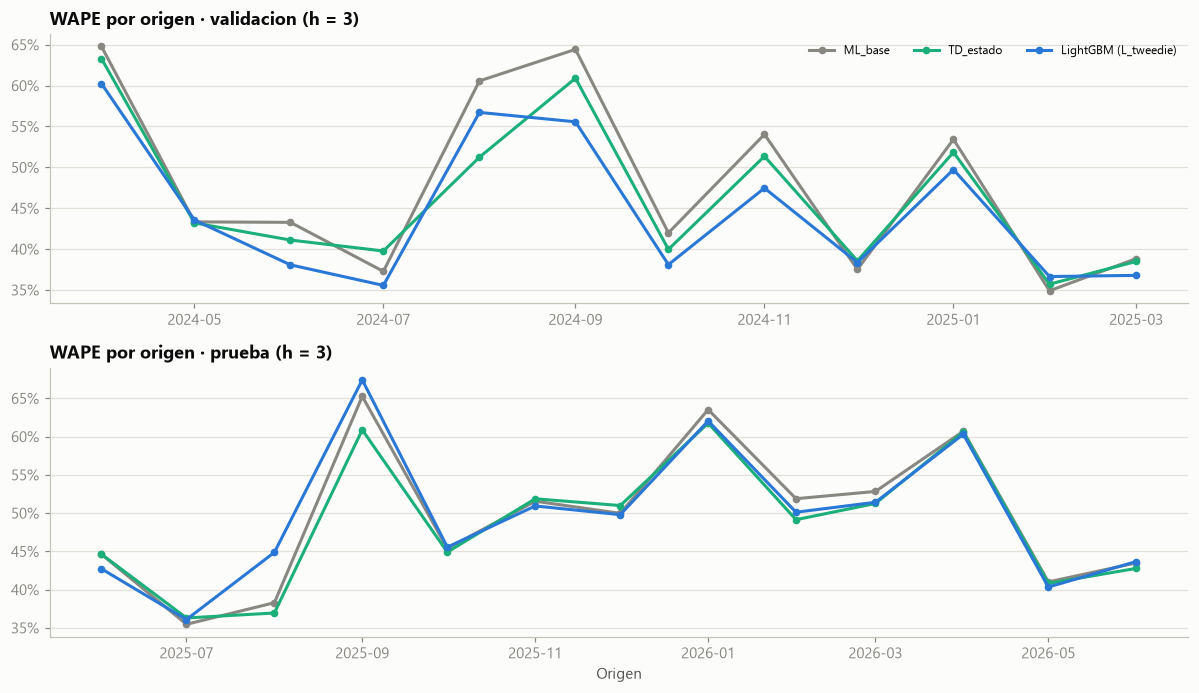

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.4), sharex=False)
for a, p in zip(ax, PERIODOS):
    po = por_origen(d[p], ["ML_base", ELEGIDO, "TD_estado"])
    a.plot(po.index, po.ML_base, marker="o", ms=4, color=GRIS, label="ML_base")
    a.plot(po.index, po.TD_estado, marker="o", ms=4, color=COLORES[2], label="TD_estado")
    a.plot(po.index, po[ELEGIDO], marker="o", ms=4, color=AZUL, label=f"LightGBM ({ELEGIDO})")
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    a.set_title(f"WAPE por origen · {p} (h = 3)")
ax[0].legend(fontsize=8, ncol=3)
ax[1].set_xlabel("Origen")
fig.tight_layout()
fig.savefig(FIG / "31_lgbm_wape_origen.png"); plt.show()

En validación, `L_tweedie` queda abajo en casi todos los orígenes de la caída de 2024 (jun-2024 → ene-2025). En
prueba las tres curvas casi se enciman. La excepción es ago-2025, donde LightGBM queda 6.6 pp peor (0.449 vs 0.383).

## 4. ¿De dónde sale la ganancia de validación?

### 4.1 Algoritmo vs pérdida

- `L_A` − `ML_base`: mismo objetivo Poisson y mismos hiperparámetros; la diferencia es solo el **algoritmo**.
- `L_tweedie` − `L_A`: mismo algoritmo; la diferencia es solo la **pérdida** (Tweedie vs Poisson).

In [5]:
filas = []
for p in PERIODOS:
    w, s = wape(d[p], ["ML_base", "L_A", ELEGIDO]), sesgo(d[p], ["ML_base", "L_A", ELEGIDO])
    filas.append({"periodo": p, "Δ WAPE algoritmo (pp)": (w.L_A - w.ML_base) * 100,
                  "Δ WAPE pérdida (pp)": (w[ELEGIDO] - w.L_A) * 100,
                  "Δ sesgo algoritmo (pp)": (s.L_A - s.ML_base) * 100,
                  "Δ sesgo pérdida (pp)": (s[ELEGIDO] - s.L_A) * 100})
print(pd.DataFrame(filas).set_index("periodo").round(2).to_string())

            Δ WAPE algoritmo (pp)  Δ WAPE pérdida (pp)  Δ sesgo algoritmo (pp)  Δ sesgo pérdida (pp)
periodo                                                                                             
validacion                  -0.78                -2.09                   -3.49                 -4.53
prueba                       0.36                -0.26                    0.41                 -0.13


**LightGBM por sí solo no aporta:** con los mismos hiperparámetros, `L_A` queda −0.8 pp en validación (7/12
orígenes, no pasa la regla) y +0.4 pp en prueba (6/13). Los dos algoritmos son implementaciones del mismo método
(gradient boosting con histogramas), así que es lo esperado. Lo que más movió la validación fue la **pérdida
Tweedie** (−2.1 pp de WAPE y −4.5 pp de sesgo sobre `L_A`), que recorta el sobre-pronóstico. En prueba, donde
`ML_base` casi no tiene sesgo (+3.5 %), no hay qué recortar y la ventaja desaparece (−0.3 pp).

### 4.2 Por clase Syntetos–Boylan, por volumen del SKU y por estado de la familia

In [6]:
def tabla_por(x, grupo, mods=("ML_base", "L_A", ELEGIDO)):
    g = x.groupby(grupo, observed=True)
    t = pd.DataFrame({f"WAPE {m}": g.apply(lambda z: wape(z, [m]).iloc[0]) for m in mods})
    for m in ("ML_base", ELEGIDO):
        t[f"sesgo {m}"] = g.apply(lambda z: sesgo(z, [m]).iloc[0])
    t["% unidades"] = g.y.sum() / x.y.sum()
    return t

for p in PERIODOS:
    x = d[p].copy()
    x["volumen"] = pd.qcut(x.groupby("id_articulo").y.transform("sum").rank(method="first"), 5,
                           labels=["Q1 (chico)", "Q2", "Q3", "Q4", "Q5 (grande)"])
    print(f"===== {p}")
    for grupo in ("clase", "volumen", "estado"):
        print(tabla_por(x, grupo).round(3).to_string()); print()

===== validacion
              WAPE ML_base  WAPE L_A  WAPE L_tweedie  sesgo ML_base  sesgo L_tweedie  % unidades
clase                                                                                           
errática             0.620     0.636           0.600          0.231            0.168       0.350
grumosa              1.060     1.006           0.941          0.060           -0.131       0.009
intermitente         2.425     2.322           1.761          1.115            0.350       0.000
suave                0.378     0.358           0.347          0.174            0.086       0.641

             WAPE ML_base  WAPE L_A  WAPE L_tweedie  sesgo ML_base  sesgo L_tweedie  % unidades
volumen                                                                                        
Q1 (chico)         26.614    20.561          13.299         25.619           12.029       0.000
Q2                  1.566     1.497           1.392          0.928            0.666       0.005
Q3              

- **Por clase:** en validación, `L_tweedie` mejora en todas las clases, sobre todo en **intermitentes** (WAPE 1.76
  vs 2.43, sesgo +35 % vs +112 %) y grumosas. Son las clases para las que se pensó Tweedie, pero pesan ~1 % de las
  unidades. En prueba la ventaja se queda solo en grumosas e intermitentes (−2 a −3 pp); en **suaves y erráticas**,
  que son el 99 % de las unidades, empata.
- **Por volumen:** en prueba, los SKUs del quintil más grande (88 % de las unidades) definen el WAPE, y ahí empatan
  (0.457 vs 0.454). La mejora está en los quintiles chicos. Eso explica que el MASE mejore y el WAPE no.
- **Por estado de la familia:** en validación la ganancia es mayor en familias **en caída** (sesgo +10 % vs +20 %),
  el mismo hueco que cubre `TD_estado` (LOG #44–#45). En prueba LightGBM mejora un poco en caída (−1.6 pp) y
  empeora en subida (+1.4 pp).

## 5. LightGBM dentro de `TD_estado`

`TD_estado` usa `ML_base` para las familias estables. Aquí se cambia solo esa pieza por `L_tweedie` (`TD_estado_L`).
Las ramas de caída y subida (`TD_mix_k3` y `TD_mix_k12`) quedan igual, aunque siguen repartiendo con la cuota de
`ML_base`.

In [7]:
filas = []
for p in PERIODOS:
    x = d[p]
    x["TD_estado_L"] = regla_estado(x, ref=ELEGIDO)
    r = resumen(x, ["TD_estado", "TD_estado_L"])[["WAPE", "sesgo", "MASE", "WAPE_total"]]
    for m in ["TD_estado", "TD_estado_L"]:
        po = por_origen(x, [m, "TD_estado"])
        filas.append({"periodo": p, "modelo": m, **r.loc[m].to_dict(),
                      "cumple vs ML_base": adopta(x, m, "ML_base"),
                      "cumple vs TD_estado": adopta(x, m, "TD_estado") if m != "TD_estado" else "",
                      "gana_origenes_vs_TD": f"{(po[m] < po.TD_estado).sum()}/{len(po)}" if m != "TD_estado" else ""})
print(pd.DataFrame(filas).set_index(["periodo", "modelo"]).round(4).to_string())

                          WAPE   sesgo    MASE  WAPE_total  cumple vs ML_base cumple vs TD_estado gana_origenes_vs_TD
periodo    modelo                                                                                                    
validacion TD_estado    0.4556  0.1520  0.7712      0.2042               True                                        
           TD_estado_L  0.4404  0.1142  0.7379      0.1730               True                True                9/12
prueba     TD_estado    0.4822  0.0160  0.9420      0.0875               True                                        
           TD_estado_L  0.4836  0.0214  0.9316      0.0897               True               False                7/13


`TD_estado_L` cumple la regla contra `ML_base` en los dos periodos, igual que `TD_estado`. Contra `TD_estado`
repite el patrón: gana en validación (0.440 vs 0.456) y empata en prueba (0.484 vs 0.482, 7/13). No hay evidencia
para cambiar la pieza estable.

## 6. Total mensual en prueba

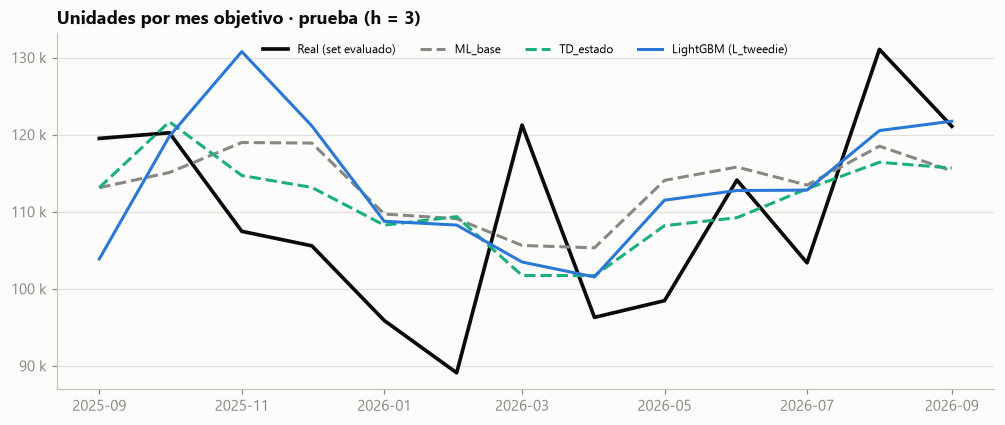

Error del total (pronóstico − real) / real:
mes_obj    2025-09-01  2025-10-01  2025-11-01  2025-12-01  2026-01-01  2026-02-01  2026-03-01  2026-04-01  2026-05-01  2026-06-01  2026-07-01  2026-08-01  2026-09-01
ML_base        -0.053      -0.043       0.107       0.126       0.144       0.224      -0.129       0.094       0.159       0.015       0.098      -0.096      -0.048
L_tweedie      -0.131      -0.004       0.217       0.147       0.134       0.215      -0.147       0.054       0.132      -0.012       0.091      -0.080       0.005
TD_estado      -0.053       0.012       0.067       0.072       0.129       0.227      -0.161       0.056       0.099      -0.043       0.093      -0.112      -0.045


In [8]:
x = d["prueba"]
tot = x.groupby("mes_obj")[["y", "ML_base", ELEGIDO, "TD_estado"]].sum()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(tot.index, tot.y, color="#0b0b0b", lw=2.4, label="Real (set evaluado)")
ax.plot(tot.index, tot.ML_base, color=GRIS, ls="--", label="ML_base")
ax.plot(tot.index, tot.TD_estado, color=COLORES[2], ls="--", label="TD_estado")
ax.plot(tot.index, tot[ELEGIDO], color=AZUL, label=f"LightGBM ({ELEGIDO})")
ax.yaxis.set_major_formatter(FMT_MILES)
ax.set_title("Unidades por mes objetivo · prueba (h = 3)")
ax.legend(fontsize=8, ncol=4)
fig.savefig(FIG / "32_lgbm_total_prueba.png"); plt.show()
e = tot[["ML_base", ELEGIDO, "TD_estado"]].sub(tot.y, axis=0)
print("Error del total (pronóstico − real) / real:")
print((e.div(tot.y, axis=0)).round(3).T.to_string())

## 7. Importancia de variables (ganancia, último origen de prueba)

Es la importancia por *gain* de LightGBM, normalizada a 1. Sirve para revisar que el modelo usa las mismas señales que
`ML_base`, no para hacer selección de variables.

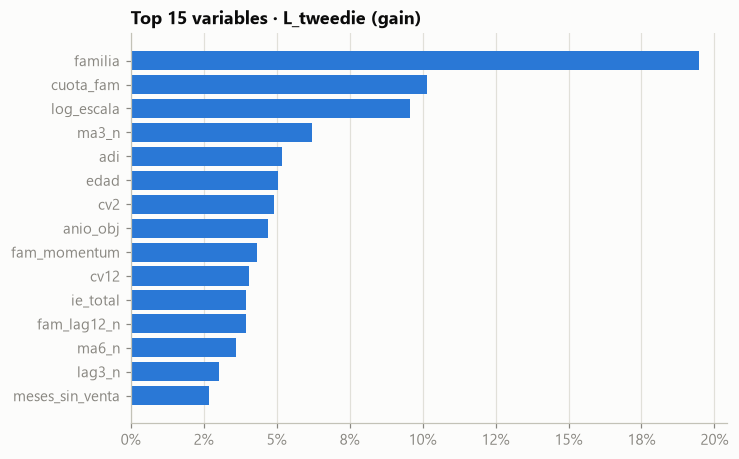

In [9]:
imp = pd.read_parquet(RES / "lgbm_importancia.parquet").gain.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp.index, imp.values, color=AZUL)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title(f"Top 15 variables · {ELEGIDO} (gain)")
fig.savefig(FIG / "33_lgbm_importancia.png"); plt.show()

`familia`, `cuota_fam` y `log_escala` concentran ~40 % de la ganancia: el modelo aprende sobre todo el **nivel**
de cada SKU dentro de su familia. Siguen `ma3_n` (nivel reciente), las medidas de intermitencia (`adi`, `cv2`) y la
edad. Son las mismas señales que ya explican a `ML_base` (`reports/FEATURES.md`).

## 8. Hallazgos y decisión

1. **LightGBM no se adopta.** La configuración elegida en validación (`L_tweedie`) le gana con claridad a `ML_base`
   en validación (WAPE 0.441 vs 0.469, 9/12 orígenes, sesgo +11 % vs +19 %), pero **empata en prueba** (0.491 vs
   0.490, 8/13, sesgo +3.8 % vs +3.5 %) y queda detrás de `TD_estado` (0.482). La regla WAPE + sesgo no se cumple
   en prueba ni contra `ML_base` ni contra `TD_estado`. Es el mismo patrón de LOG #20: lo que gana con holgura
   en un periodo y no se sostiene en el otro se trata como ruido de selección.
2. **El algoritmo no es la palanca.** Con los mismos hiperparámetros y la misma pérdida, LightGBM (`L_A`) y
   HistGradientBoosting dan prácticamente lo mismo (−0.8 pp en validación, +0.4 pp en prueba). Los dos implementan
   gradient boosting con histogramas. El muestreo de filas y columnas (`L_bag`) no ayuda.
3. **La pérdida Tweedie sí cambia algo, pero no basta.** Recorta el sobre-pronóstico (−4.5 pp de sesgo en
   validación) y mejora a los SKUs intermitentes y chicos (mejor MASE en los dos periodos: 0.709 vs 0.788 y
   0.933 vs 0.952). La ganancia en WAPE de validación vino sobre todo de familias **en caída**, el mismo sesgo que
   ya corrige `TD_estado`. Cuando el periodo no tiene ese sesgo (prueba), no queda ventaja en los SKUs grandes,
   que definen el WAPE.
4. **Meter LightGBM en la rama estable de `TD_estado` tampoco cambia la decisión:** `TD_estado_L` empata con
   `TD_estado` en prueba (0.484 vs 0.482, 7/13).
5. **Costo:** ~1.6 s por ajuste mensual (`L_tweedie`, ~110 mil filas). El tiempo no es un factor; el criterio queda
   solo en la precisión.
6. **Qué se queda en observación:** `L_tweedie` como candidato en cada reentrenamiento mensual, igual que el resto
   de las variantes. Si en una caída futura `TD_estado` vuelve a arrastrar sesgo, Tweedie es la primera opción a
   reevaluar. La alternativa más barata de probar es la pérdida Tweedie dentro del propio `ML_base`: scikit-learn
   no la ofrece en HistGradientBoosting, así que eso requeriría migrar el regresor a LightGBM.

**Modelo vigente sin cambios:** `TD_estado` (LOG #45) para los SKUs maduros. Inventario y pedido no se recalcularon
porque el pronóstico elegido no cambia.